<center>
  <h1>Lei de Lambert Fuzzy 🧪🤔</h1>
  <b>Yasmin B. Shimizu & Vinícius F. Wasques</b>
</center>

<p style="text-align: center;">
  Parte do Projeto de Iniciação Científica <b>Estudo de interatividade e aritmética fuzzy com aplicações em quadrados mínimos fuzzy e problemas inversos</b> (FAPESP n° 2025/26138-6) para a III Semana de Iniciação Científica da Sociedade Brasileira de Matemática (SENIC-SBM 2026).
</p>

<center>
  <img src="https://github.com/yasminbshimizu/IC_Fuzzy_Aritmetica_Interatividade_QuadradosMinimosPI/blob/main/Images/logo_fapesp_ilum_sfundo.png?raw=true" width="1000"/>
</center>



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 🎲 Metodologia

#### Tratamento de dados

Para este trabalho, foram utilizados os dados de absorbância por concentração disponibilizados por Shimizu, et al. (2025)[3] em formato .txt via <a href="https://github.com/yasminbshimizu/Lei_de_Lambert_Fuzzy"> repositório Github </a> e foram importados neste notebook através da célula abaixo.

 <div class="alert alert-warning">
  <div style="text-align: center; font-size: 14px"> ⚠️ Para o funcionamento desta célula, é necessário que o arquivo <code>data_CoCl2.txt</code> esteja baixado no mesmo diretório em que o notebook está sendo executado!! </div>
</div>   

In [2]:
%%time

df = pd.read_csv("data_CoCl2.txt", sep = ";", skiprows = 20)

df = df[:63]
concentracao_CoCl2 = [0, 2, 1.9, 1.8, 1.7, 1.6, 1.5, 1.4, 1.3, 1.2, 1.1, 1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]
concentracao_final = concentracao_CoCl2[1:]

concentracao = []
for x in concentracao_CoCl2:
        concentracao.append(x)
        concentracao.append(x)
        concentracao.append(x)

df["Concentração"] = concentracao
df = df.rename(columns={'A492': 'Absorbância'})
df

CPU times: total: 15.6 ms
Wall time: 11.6 ms


,Well,Name,Absorbância,Concentração
0,A1,Sample 1.1,0.029,0.0
1,A2,Sample 1.2,0.031,0.0
2,A3,Sample 1.3,0.028,0.0
3,A4,Sample 1.4,2.866,2.0
4,A5,Sample 1.5,2.850,2.0
...,...,...,...,...
58,E11,Sample 1.59,0.322,0.2
59,E12,Sample 1.60,0.330,0.2
60,F1,Sample 1.61,0.205,0.1
61,F2,Sample 1.62,0.194,0.1


In [3]:
%%time

from lei_de_lambert_fuzzy import trata_dados, trata_dados_fuzzy
from lei_de_lambert_fuzzy import soma_fuzzy

absorb = df["Absorbância"]

absorb_final, desv_final = trata_dados(absorb)
absorb_fuzzy = trata_dados_fuzzy(absorb, soma_fuzzy)
absorb_fuzzy_interativo = trata_dados_fuzzy(absorb)

CPU times: total: 0 ns
Wall time: 6 ms


In [4]:
%%time

i_data = set(range(3, 8)) | set(range(9, 14)) | set(range(15, 20))

i_total = set(range(20))

i_prev = i_total - i_data

xr_data = np.array([concentracao_final[i] for i in i_data])
xr_prev = np.array([concentracao_final[i] for i in i_prev])
yr_data = np.array([absorb_final[i] for i in i_data])
yr_err = np.array([desv_final[i] for i in i_data])

yr_prev = np.array([absorb_final[i] for i in i_prev])
yr_err_prev = np.array([desv_final[i] for i in i_prev])

xf_data = np.array([concentracao_final[i] for i in i_data]).reshape(-1, 1)
xf_prev = np.array([concentracao_final[i] for i in i_prev]).reshape(-1, 1)
yf_data = np.array([absorb_fuzzy[i] for i in i_data])
yf_prev = np.array([absorb_fuzzy[i] for i in i_prev])
yfi_data = np.array([absorb_fuzzy_interativo[i] for i in i_data])
yfi_prev = np.array([absorb_fuzzy_interativo[i] for i in i_prev])

CPU times: total: 0 ns
Wall time: 0 ns


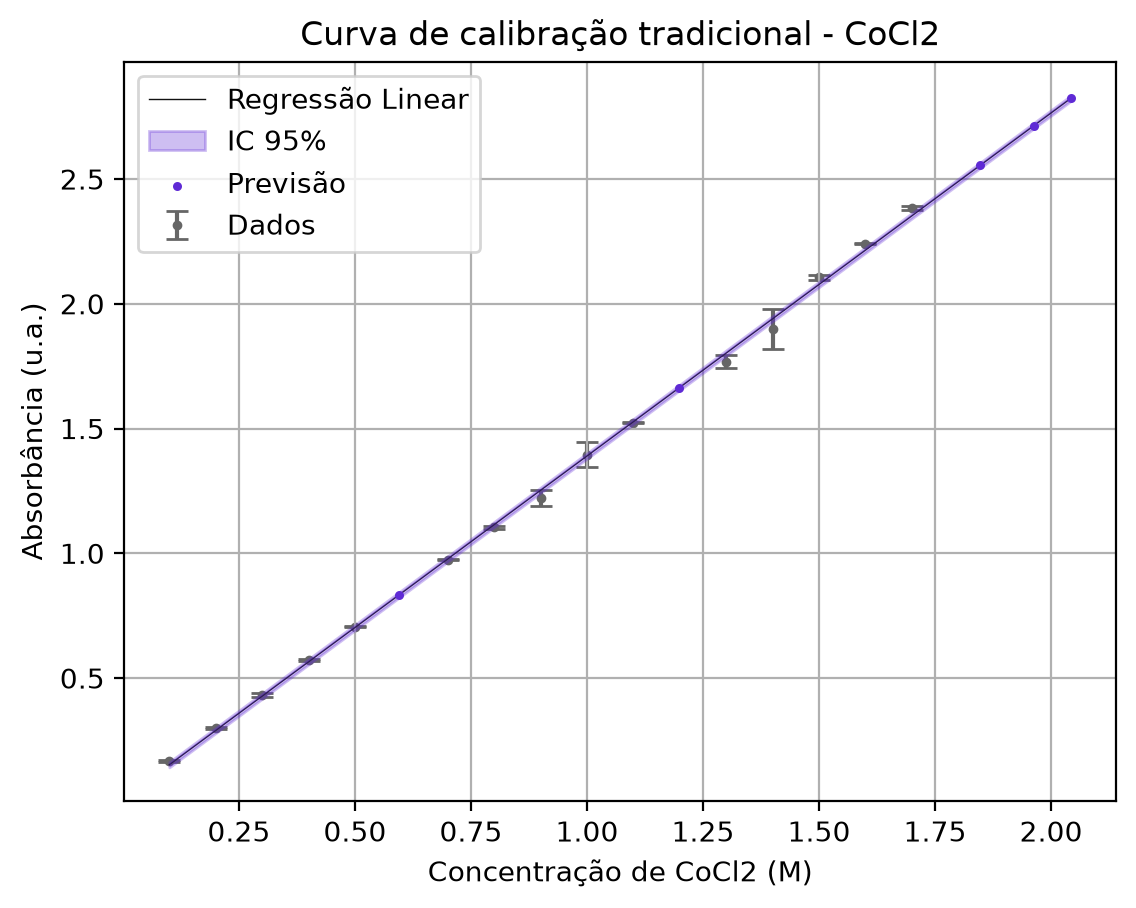

CPU times: total: 359 ms
Wall time: 477 ms


In [5]:
%%time

from lei_de_lambert_fuzzy import lei_lambert

title = "Curva de calibração tradicional - CoCl2"

coefs, conc_prev = lei_lambert(xr_data, yr_data, yr_err, abs_prev = yr_prev, titulo = title, xlabel = "Concentração de CoCl2 (M)", ylabel = "Absorbância (u.a.)")

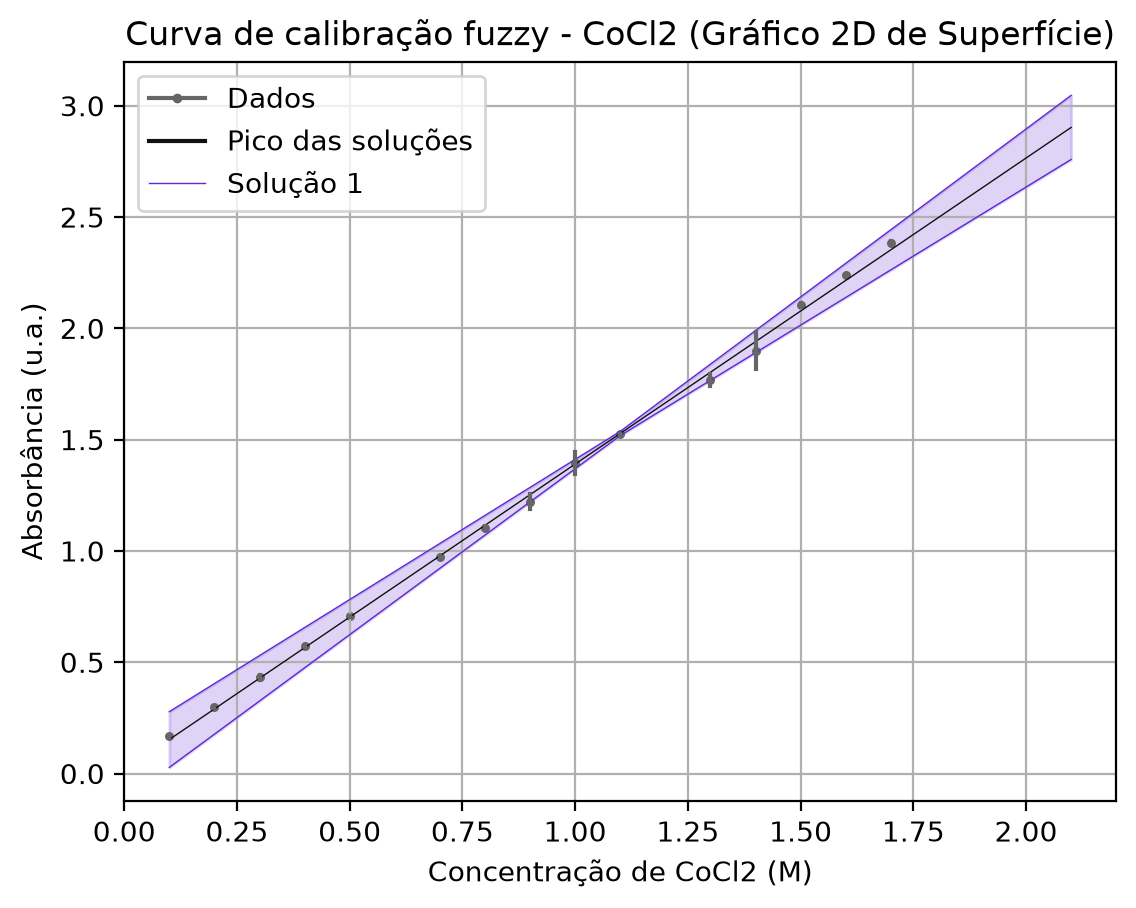

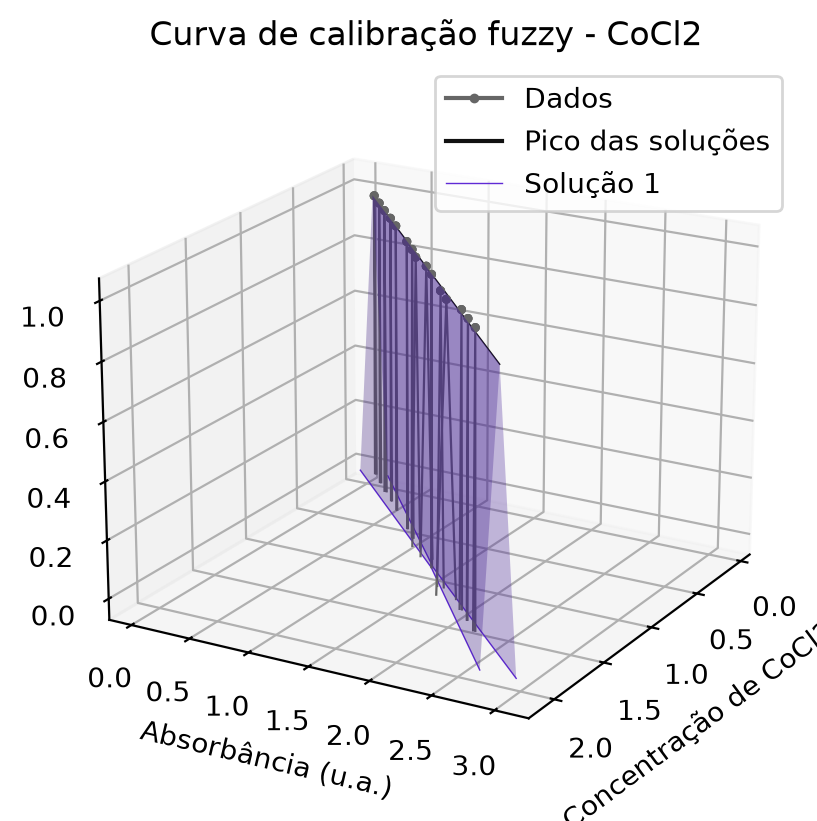

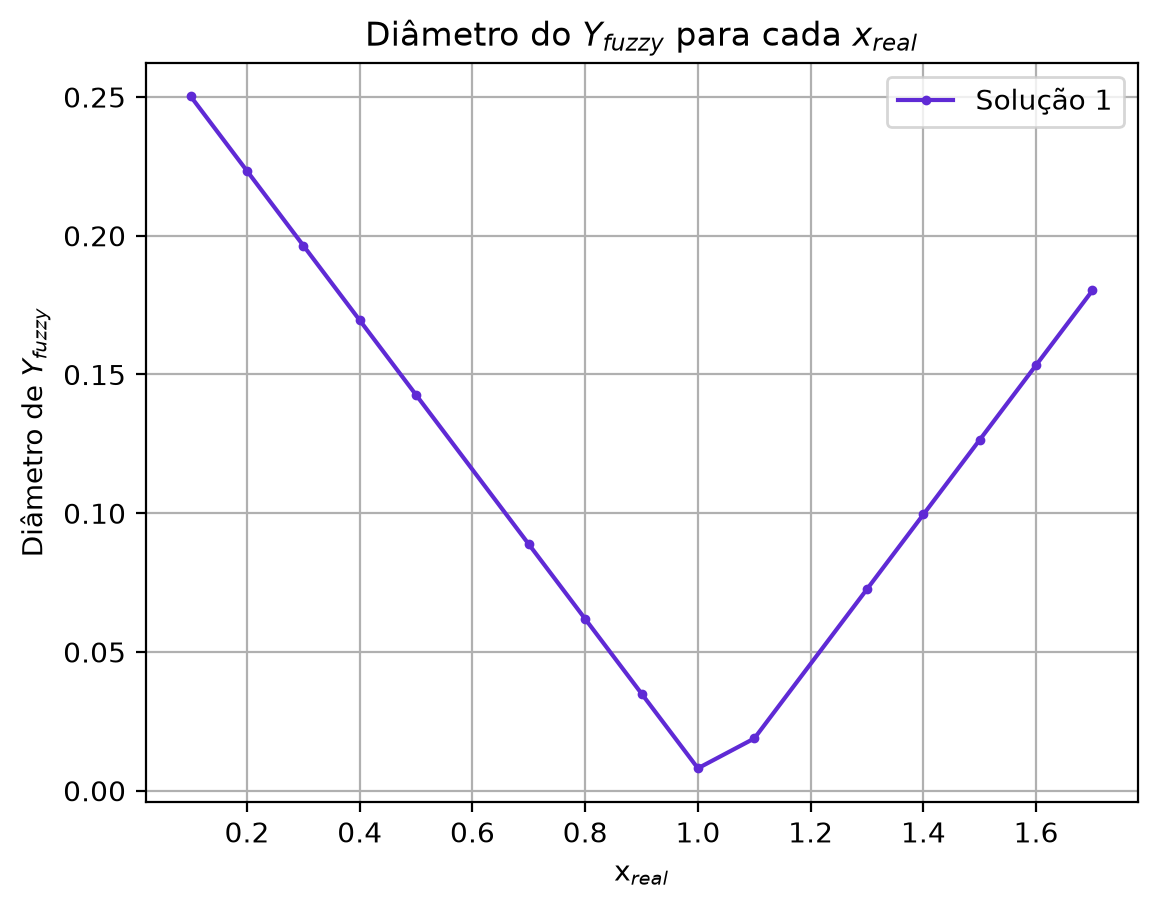

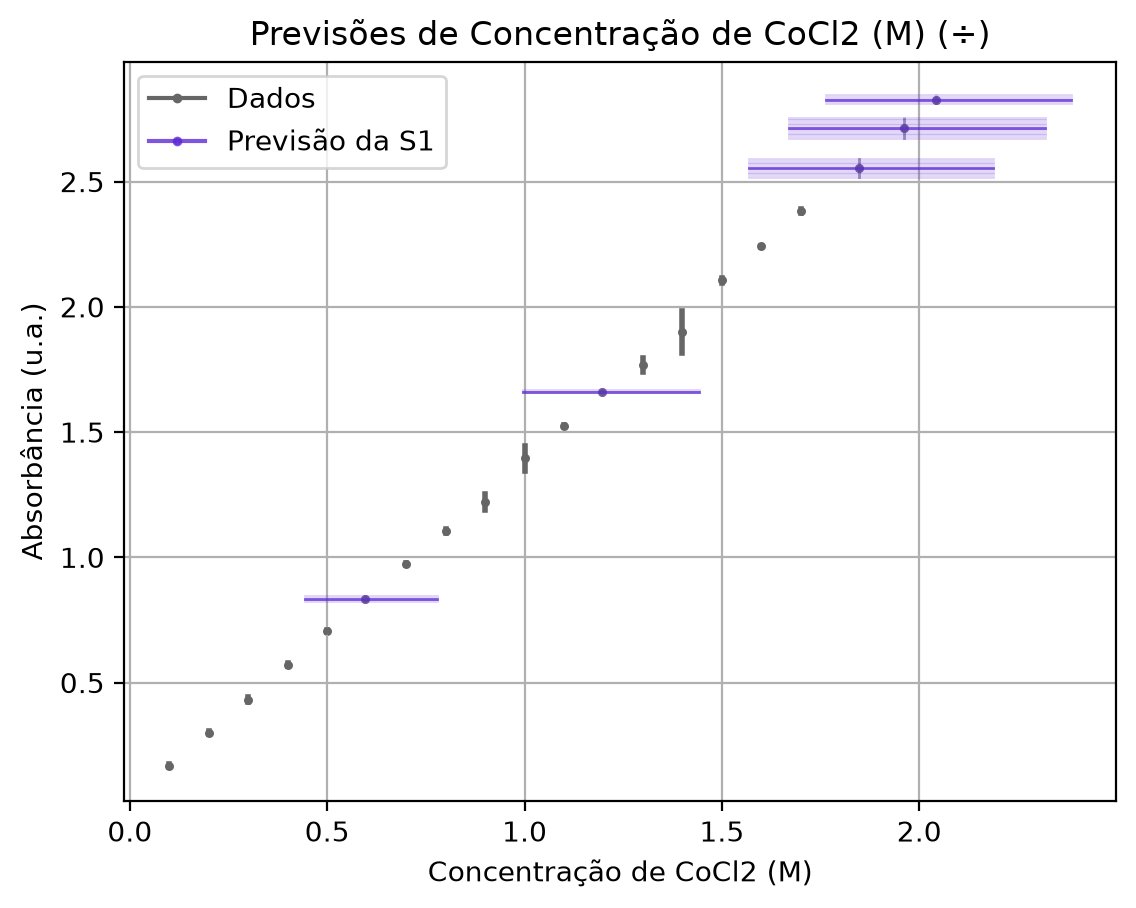

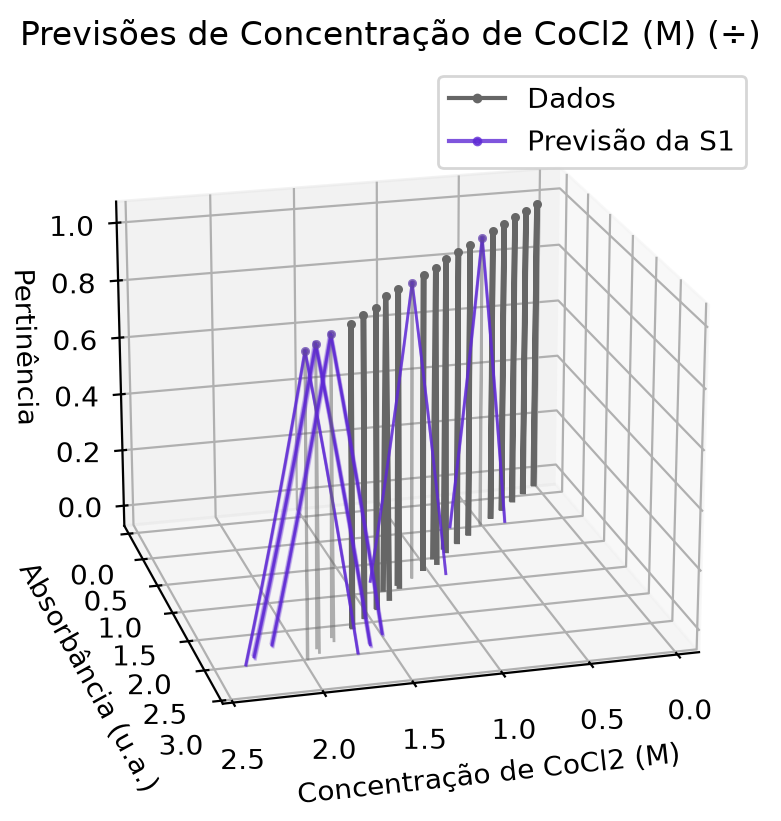

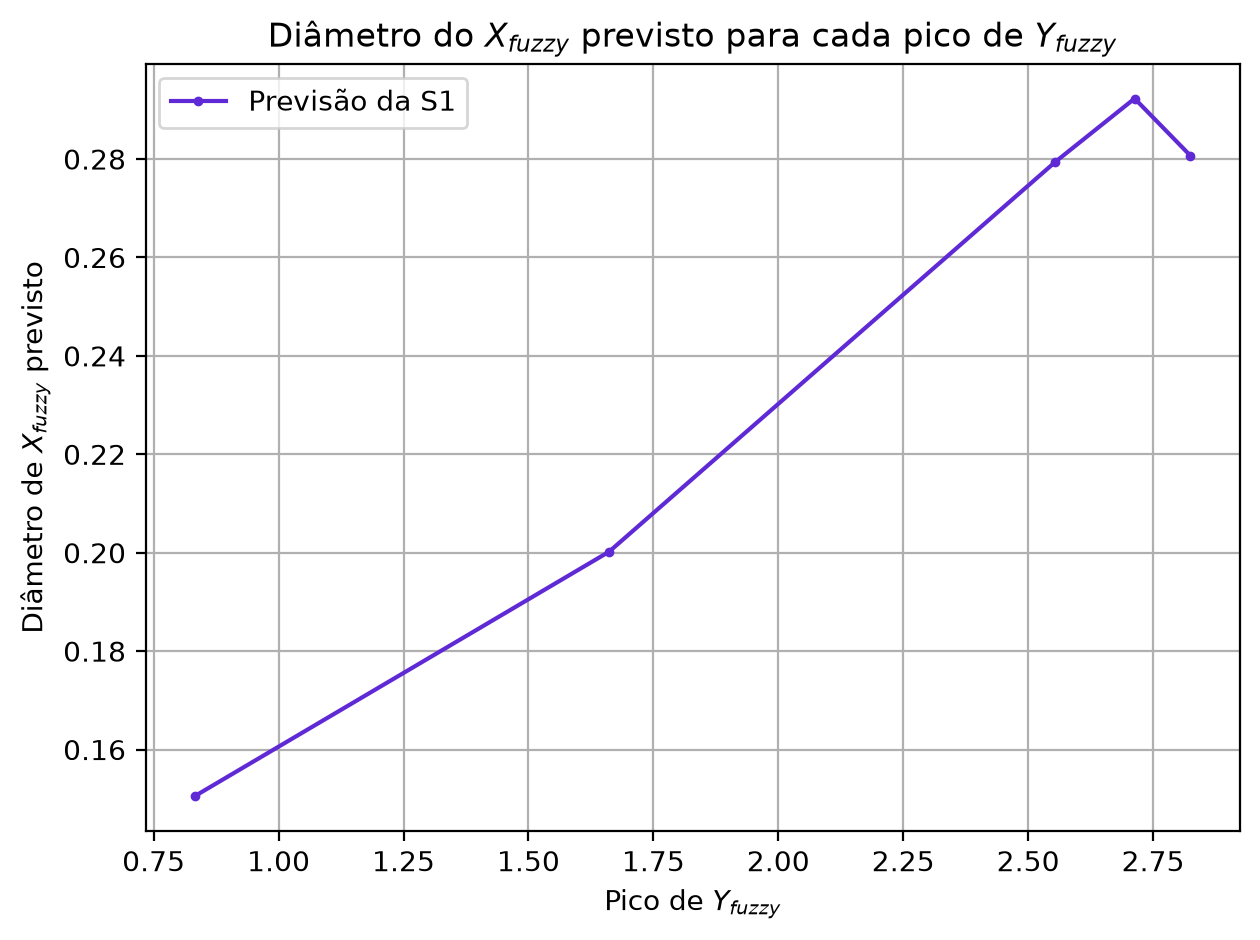

In [6]:
from lei_de_lambert_fuzzy import lei_lambert_fuzzy

title = f"Curva de calibração fuzzy - CoCl2"
sol_nintr, xp = lei_lambert_fuzzy(xf_data, yf_data, soma=soma_fuzzy, y_prev = yf_prev, titulo = title, xlabel = "Concentração de CoCl2 (M)", ylabel = "Absorbância (u.a.)")

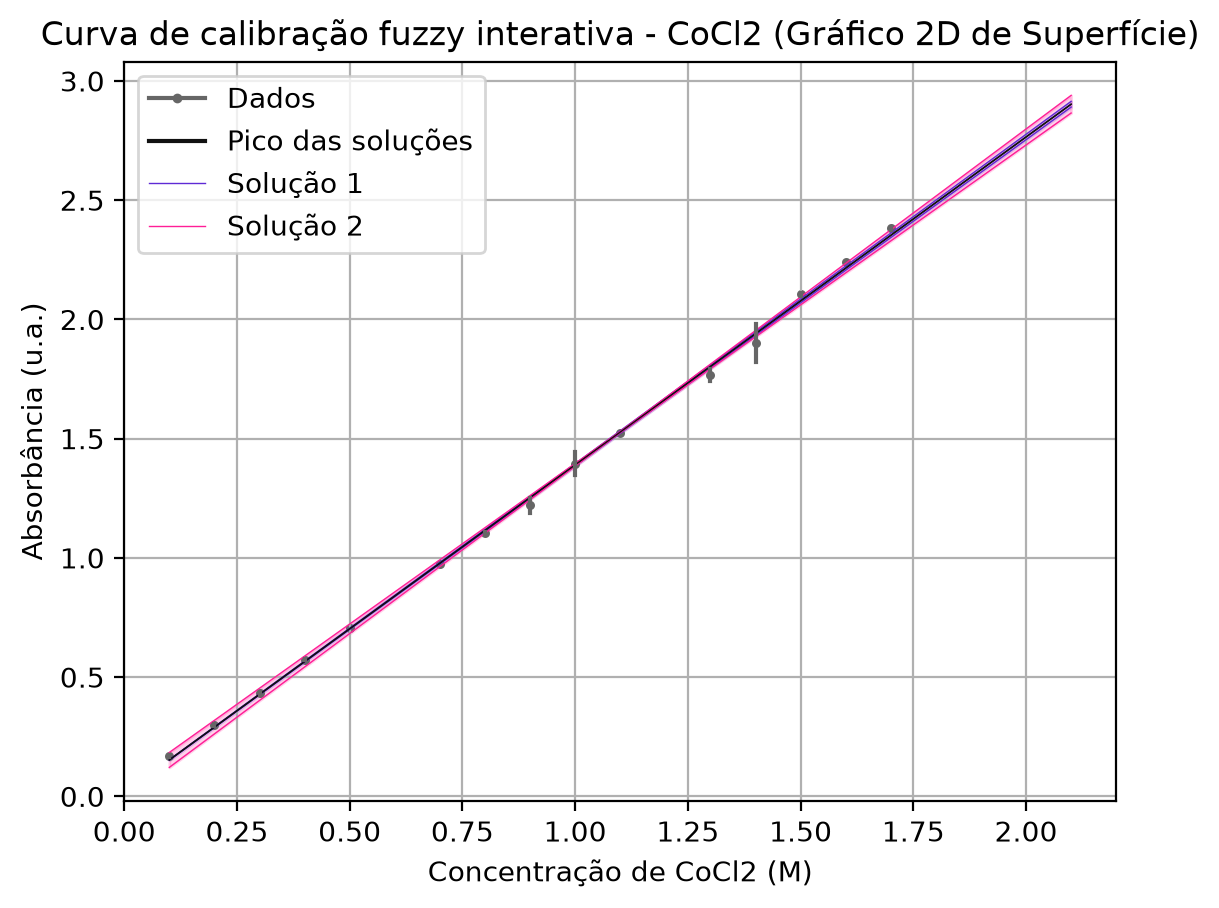

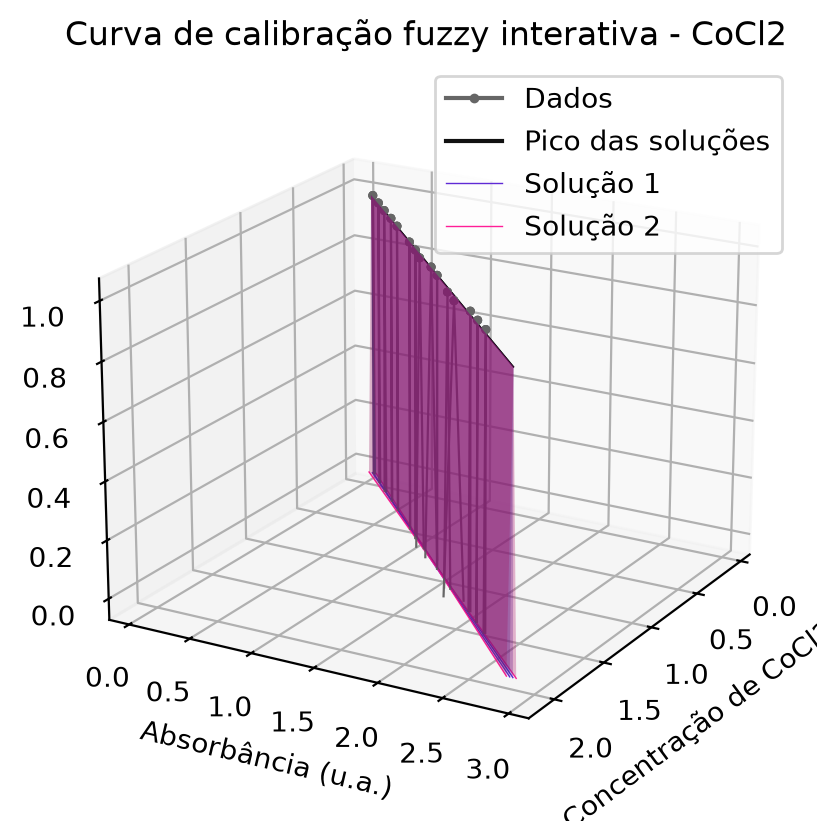

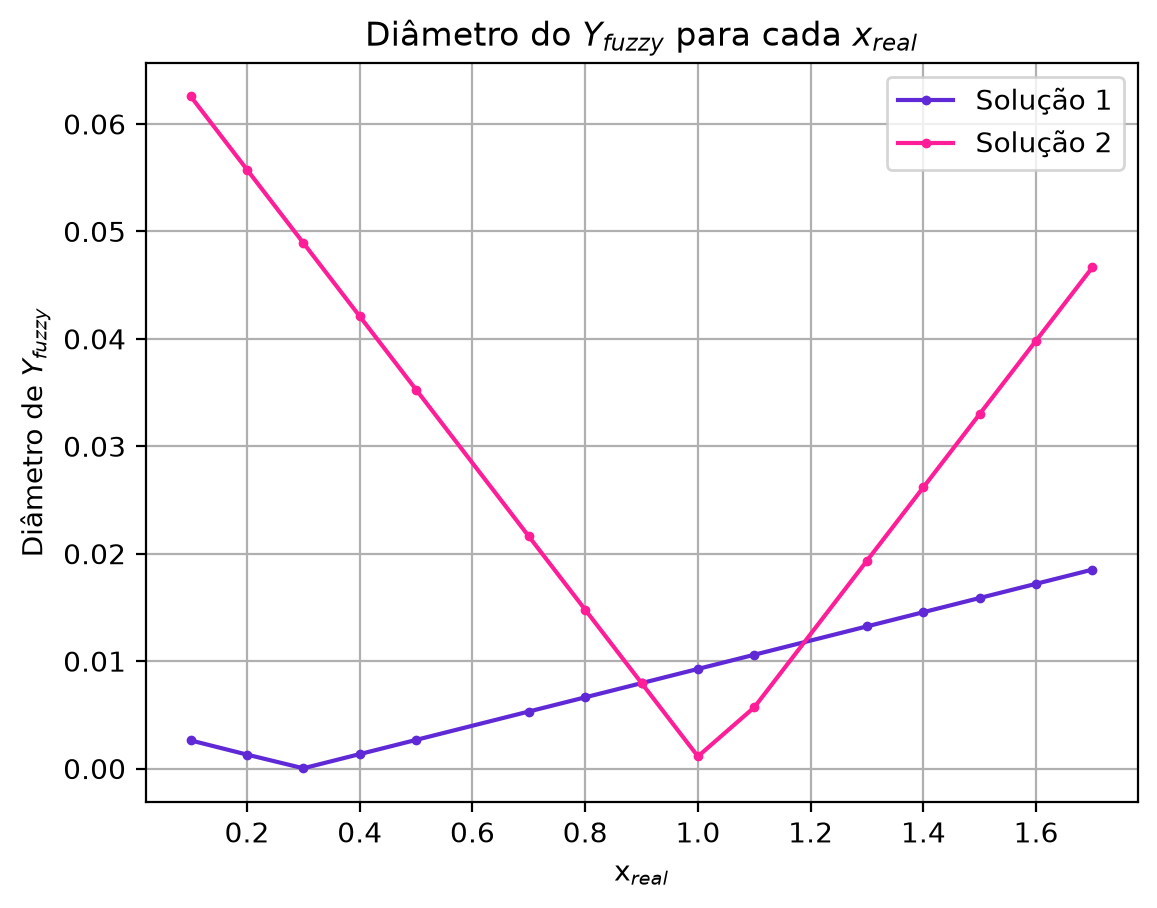

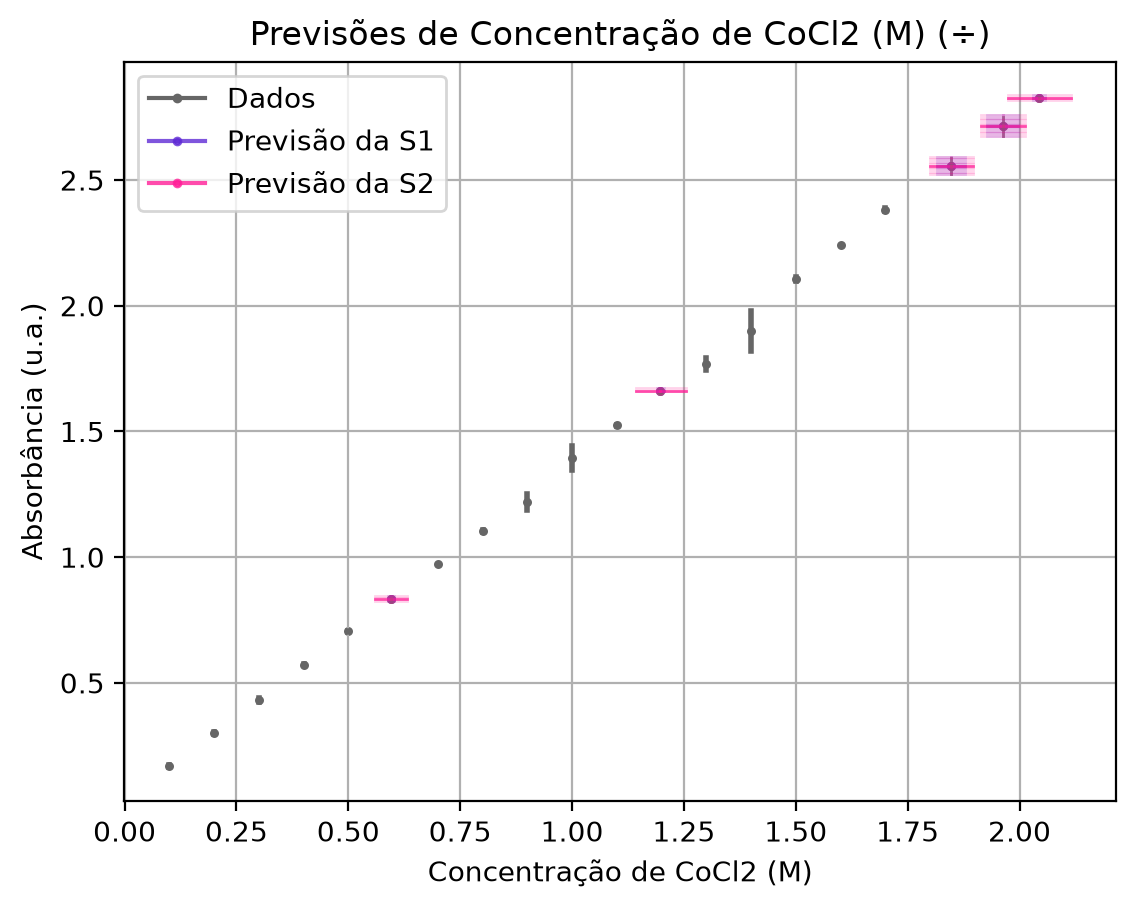

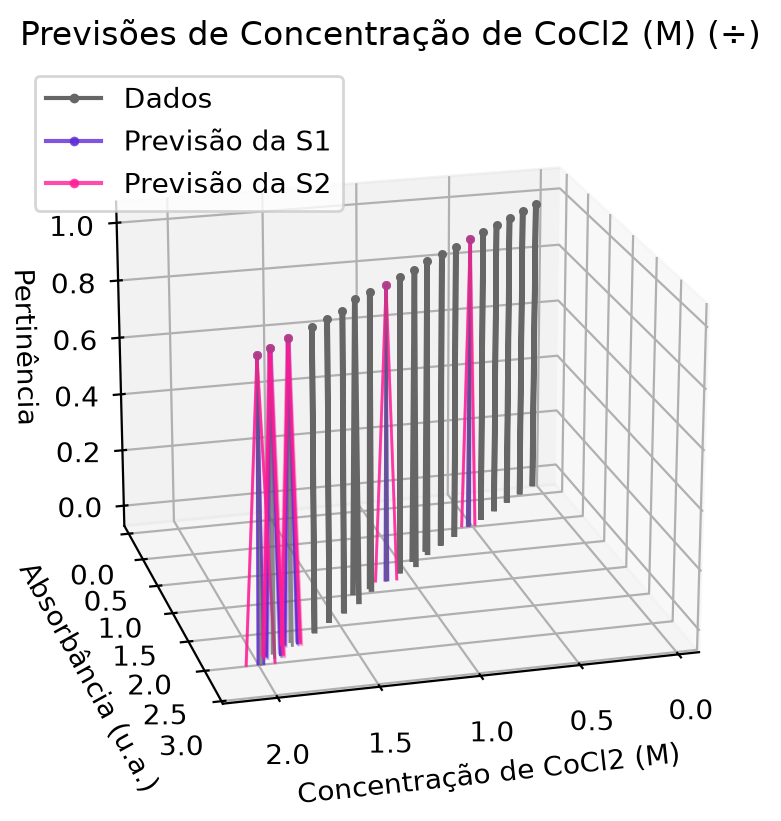

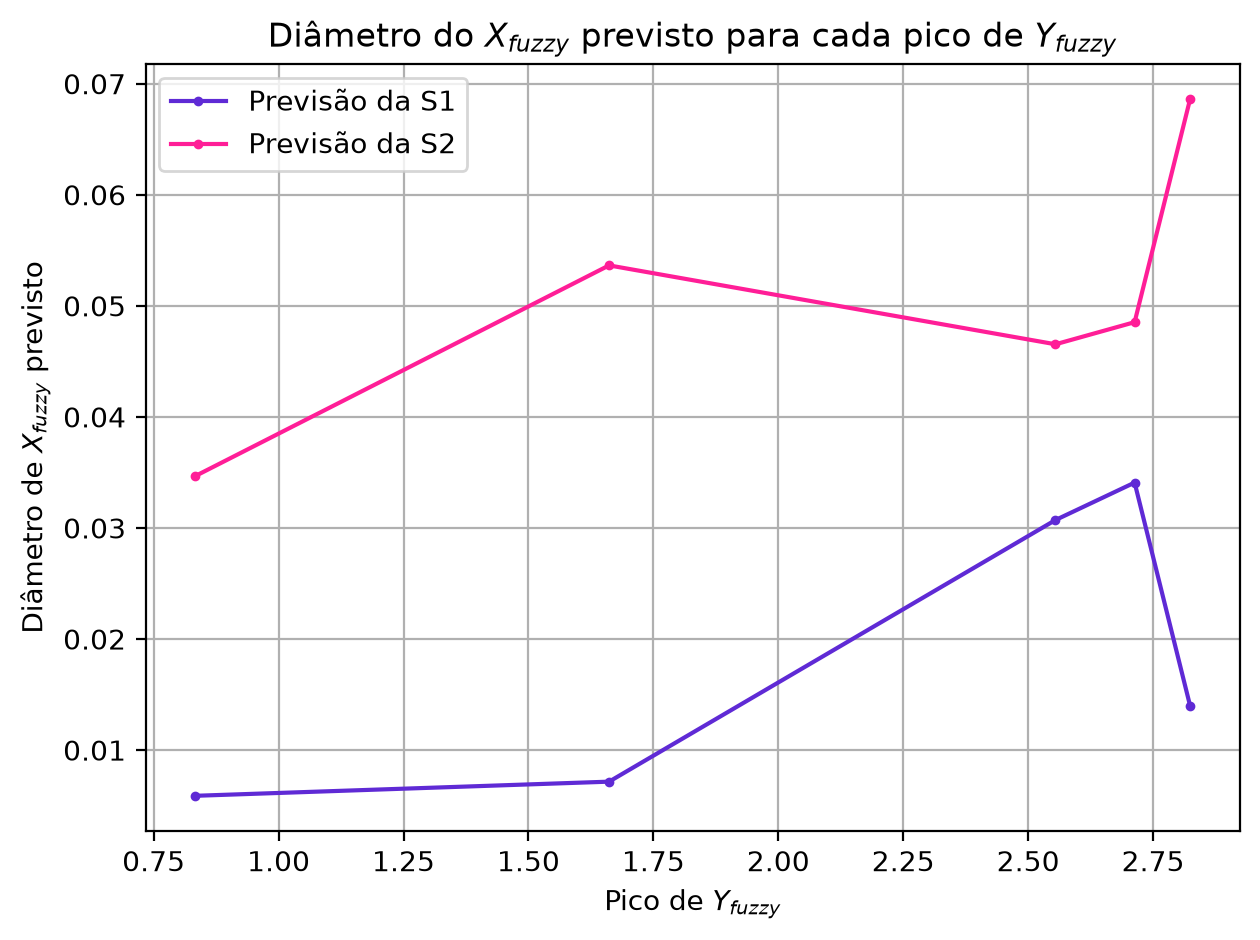

CPU times: total: 4.72 s
Wall time: 5.19 s


In [7]:
%%time

from lei_de_lambert_fuzzy import lei_lambert_fuzzy

title = f"Curva de calibração fuzzy interativa - CoCl2"

sol, xpi = lei_lambert_fuzzy(xf_data, yfi_data, y_prev = yfi_prev, titulo = title, xlabel = "Concentração de CoCl2 (M)", ylabel = "Absorbância (u.a.)")

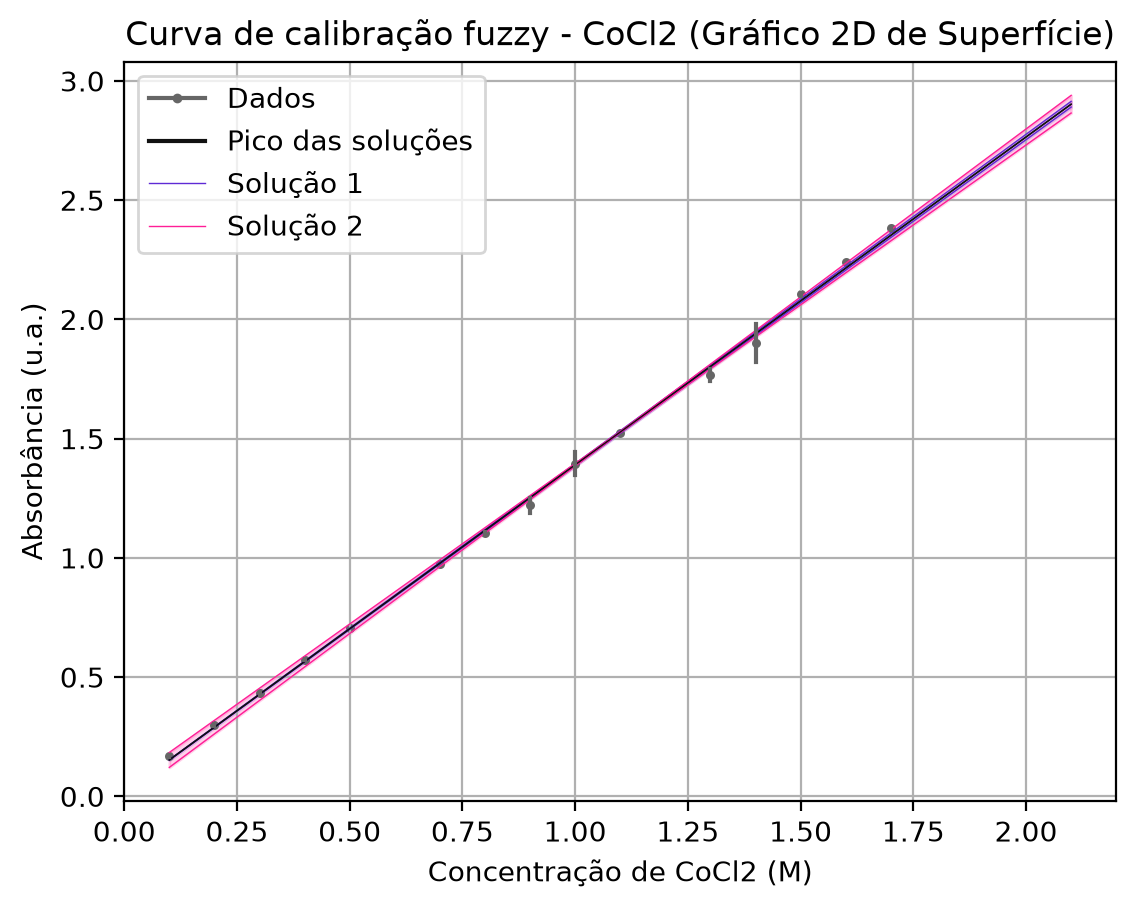

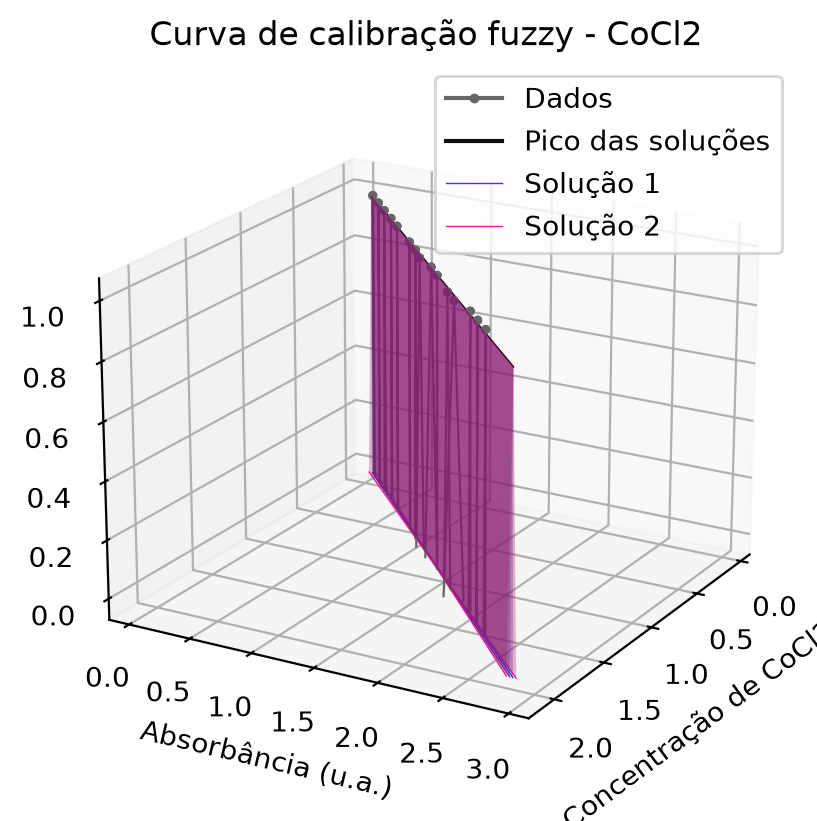

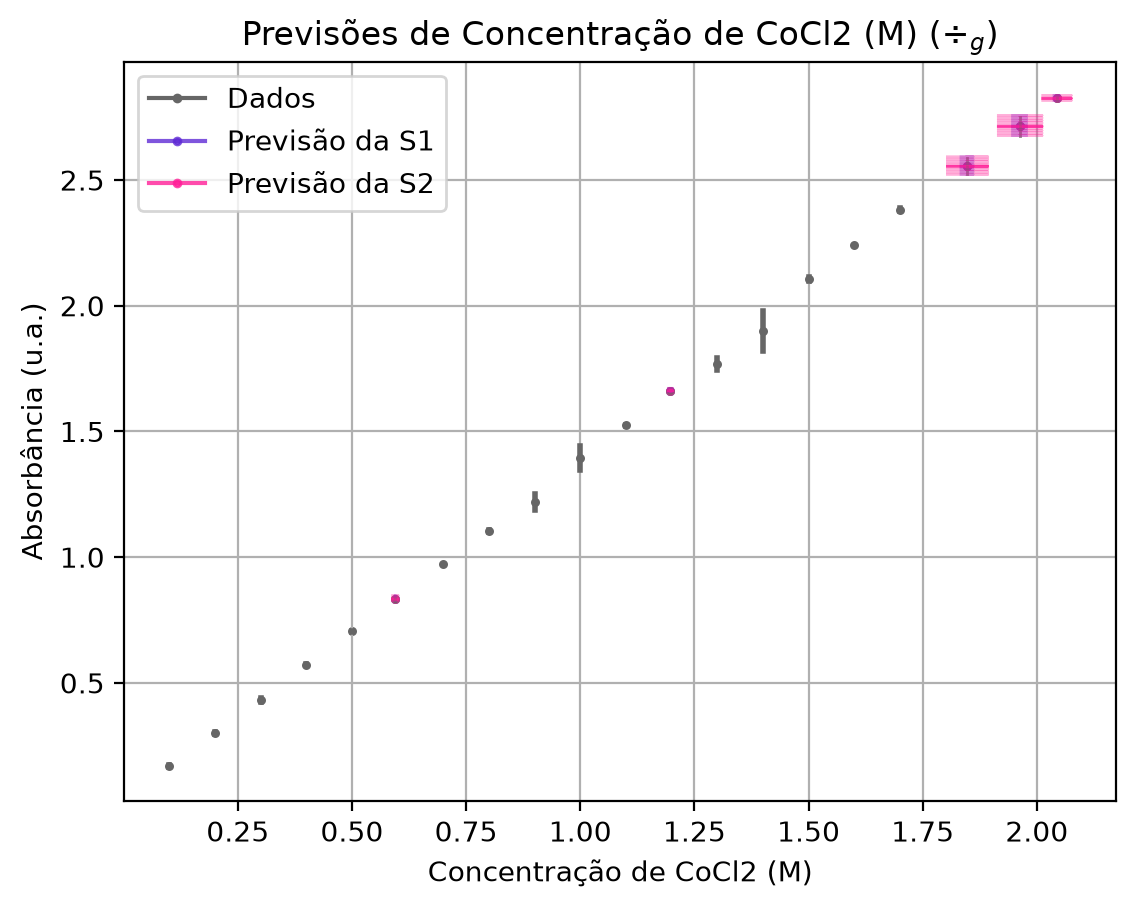

CPU times: total: 3.08 s
Wall time: 3.14 s


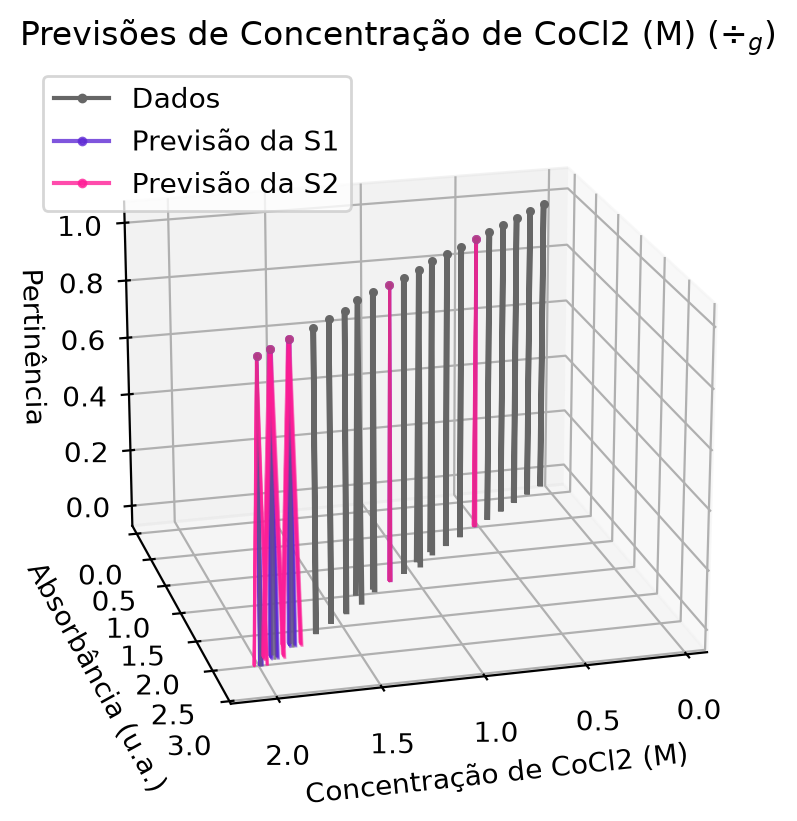

In [8]:
%%time

from lei_de_lambert_fuzzy import lei_lambert_gfuzzy

title = "Curva de calibração fuzzy - CoCl2"

gsol, xpg = lei_lambert_gfuzzy(xf_data, yfi_data, y_prev = yfi_prev, titulo = title, xlabel = "Concentração de CoCl2 (M)", ylabel = "Absorbância (u.a.)")

## 🗯️ Resultados obtidos

In [9]:
%%time

print(sol == gsol)

[[[ True  True  True]
  [ True  True  True]]

 [[ True  True  True]
  [ True  True  True]]]
CPU times: total: 0 ns
Wall time: 0 ns


In [10]:
from lei_de_lambert_fuzzy import representacao_triangular, real2fuzzy, dist_min_alpha1, metr_hausdorff, metr_maximo, entropia_shannon_ntrifuzzy, media

x_fuzzy = [real2fuzzy(xr_prev[i], 1001) for i in range(5)]
x_fprev = [real2fuzzy(conc_prev[i], 1001) for i in range(5)]
x1 = xp[0]
xi1 = xpi[0]
xi2 = xpi[1]
xg1 = [[x[:len(x)//2], x[len(x)//2:]] for x in xpg[0]]
xg2 = [[x[:len(x)//2], x[len(x)//2:]] for x in xpg[1]]

xpt1 = [representacao_triangular(x) for x in x1]
xpit1 = [representacao_triangular(x) for x in xi1]
xpit2 = [representacao_triangular(x) for x in xi2]
xptg1 = [representacao_triangular(x) for x in xg1]
xptg2 = [representacao_triangular(x) for x in xg2]

alpha_tri = [0,1,0]
alpha = np.arange(0, 1.001, 0.001).reshape((-1,1))

In [11]:
print(np.array(x_fuzzy).shape)
print(np.array(x1).shape)

(5, 2, 1001)
(5, 2, 1001)


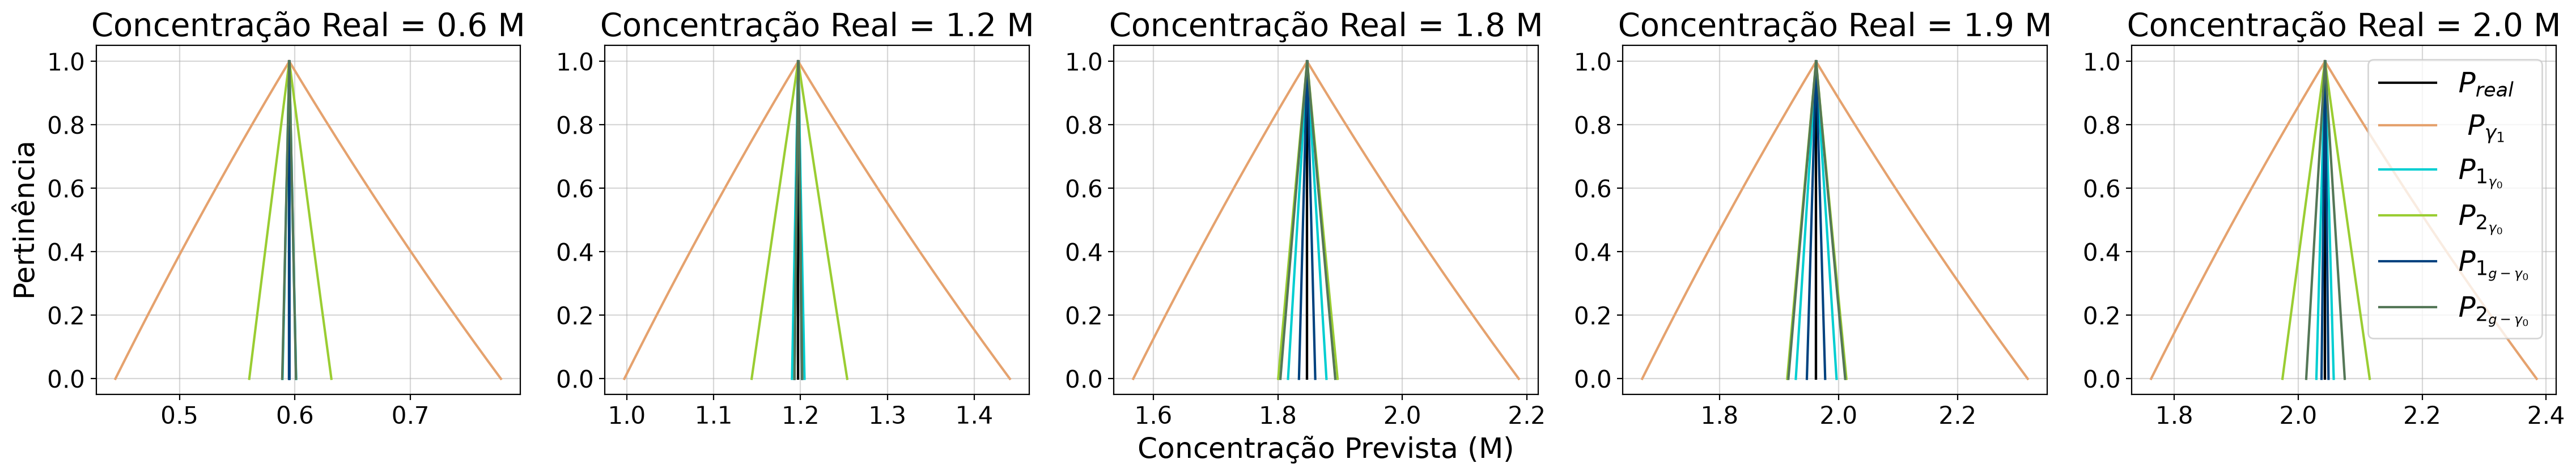

In [12]:
fig, ax = plt.subplots(1,5, figsize=(28,4), dpi=200)

for i in range(5):

    ax[4-i].plot(x_fprev[i][0], alpha, color = "black", label = r"$P_{real}$")
    ax[4-i].plot(x_fprev[i][1], alpha, color = "black")

    ax[4-i].plot(x1[i][0], alpha, color = "#e5a26e", label = r" $P_{\gamma_{1}}$")
    ax[4-i].plot(x1[i][1], alpha, color = "#e5a26e")

    ax[4-i].plot(xi1[i][0], alpha, color = "darkturquoise", label=r"$P_{1_{\gamma_0}}$")
    ax[4-i].plot(xi1[i][1], alpha, color = "darkturquoise")

    ax[4-i].plot(xi2[i][0], alpha, color = "yellowgreen", label=r"$P_{2_{\gamma_0}}$")
    ax[4-i].plot(xi2[i][1], alpha, color = "yellowgreen")

    ax[4-i].plot(xg1[i][0], alpha, color = "#00427f", label=r"$P_{1_{g-\gamma_0}}$")
    ax[4-i].plot(xg1[i][1], alpha, color = "#00427f")

    ax[4-i].plot(xg2[i][0], alpha, color = "#547757", label=r"$P_{2_{g-\gamma_0}}$")
    ax[4-i].plot(xg2[i][1], alpha, color = "#547757")

    ax[4-i].tick_params(axis="x", labelsize=15)
    ax[4-i].tick_params(axis="y", labelsize=15)
    ax[4-i].grid(alpha=0.5)
    ax[4-i].set_title(f"Concentração Real = {xr_prev[i]} M", fontsize=20)


ax[2].set_xlabel("Concentração Prevista (M)", fontsize=18)
ax[0].set_ylabel("Pertinência", fontsize=18)
ax[4].legend(loc="upper right", fontsize=18)

plt.show()

In [15]:
%time

pdist_real = []
pdist1 = []
pdisti1 = []
pdisti2 = []
pdistg1 = []
pdistg2 = []
#difs = [] 

for i in range(5):

    cr = real2fuzzy(conc_prev[i], 1001)

    dr = dist_min_alpha1(x_fuzzy[i], cr)
    pdist_real.append(dr)
    
    d1 = dist_min_alpha1(x1[i], cr)
    pdist1.append(d1)

    di1 = dist_min_alpha1(xi1[i], cr)
    pdisti1.append(di1)
    
    di2 = dist_min_alpha1(xi2[i], cr)
    pdisti2.append(di2)
    
    dg1 = dist_min_alpha1(xg1[i], cr)
    pdistg1.append(dg1)
    
    dg2 = dist_min_alpha1(xg2[i], cr)
    pdistg2.append(dg2)

    # dif = abs(e1 - e2)
    # difs.append(dif)
    
dif_real = media(pdist_real)
dif1 = media(pdist1)
difi1 = media(pdisti1)
difi2 = media(pdisti2)
difg1 = media(pdistg1)
difg2 = media(pdistg2)
#dif_med = media(difs)

CPU times: total: 0 ns
Wall time: 0 ns


In [17]:
%time

erros_real = []
erros1 = []
errosi1 = []
errosi2 = []
errosg1 = []
errosg2 = []
#difs = [] 

for i in range(5):
    er = metr_maximo([xr_prev[i]], [conc_prev[i]])
    erros_real.append(er)
    
    e1 = metr_hausdorff(x1[i], x_fuzzy[i])
    erros1.append(e1)

    ei1 = metr_hausdorff(xi1[i], x_fuzzy[i])
    errosi1.append(ei1)
    
    ei2 = metr_hausdorff(xi2[i], x_fuzzy[i])
    errosi2.append(ei2)
    
    eg1 = metr_hausdorff(xg1[i], x_fuzzy[i])
    errosg1.append(eg1)

    eg2 = metr_hausdorff(xg2[i], x_fuzzy[i])
    errosg2.append(eg2)

# dif = abs(e1 - e2)
# difs.append(dif)
    
err_real = media(erros_real)
err1 = media(erros1)
erri1 = media(errosi1)
erri2 = media(errosi2)
errg1 = media(errosg1)
errg2 = media(errosg2)
#dif_med = media(difs)

CPU times: total: 0 ns
Wall time: 0 ns


In [22]:
%time

entropia_real = []
entropia1 = []
entropiai1 = []
entropiai2 = []
entropiag1 = []
entropiag2 = []
#difs = [] 

for i in range(5):
    enr = entropia_shannon_ntrifuzzy(real2fuzzy(conc_prev[i], 1001))
    entropia_real.append(enr)
    
    en1 = entropia_shannon_ntrifuzzy(x1[i])
    entropia1.append(en1)

    eni1 = entropia_shannon_ntrifuzzy(xi1[i])
    entropiai1.append(eni1)
    
    eni2 = entropia_shannon_ntrifuzzy(xi2[i])
    entropiai2.append(eni2)
    
    eng1 = entropia_shannon_ntrifuzzy(xg1[i])
    entropiag1.append(eng1)

    eng2 = entropia_shannon_ntrifuzzy(xg2[i])
    entropiag2.append(eng2)

#dif = abs(e1 - e2)
#     difs.append(dif)

entr_real = media(entropia_real)
entr1 = media(entropia1)
entri1 = media(entropiai1)
entri2 = media(entropiai2)
entrg1 = media(entropiag1)
entrg2 = media(entropiag2)
#dif_med = media(difs)

CPU times: total: 0 ns
Wall time: 0 ns


In [24]:
%time

print("------- REGRESSÃO LINEAR -------")

print(" ")

print(f"Coeficientes do ajuste de curva real:")
print(coefs)


print(" ")

print(f"Coeficientes fuzzy não interativos para o ajuste de curva fuzzy:")
print(sol_nintr[0])

print(" ")

print(f"Coeficientes fuzzy da Solução 1 para o ajuste de curva fuzzy:")
print(sol[0])

print(" ")

print(f"Coeficientes fuzzy da Solução 2 para o ajuste de curva fuzzy:")
print(sol[1])

print(" ")
print(" ") 

print("--- PREVISÃO DE CONCENTRAÇÃO ---")

print(" ")

print(f"Concentrações reais para previsão:")
print(xr_prev)

print(" ")

print(f"Previsão de concentração real:")
print(conc_prev)

print(" ")

print(f"Previsão de concentração fuzzy pela solução 1:")
print(xpt1)

print(" ")

print(f"Previsão de concentração fuzzy interativa pela solução 1:")
print(xpit1)

print(" ")

print(f"Previsão de concentração fuzzy interativa pela solução 2:")
print(xpit2)

print(" ")

print(r"Previsão de concentração fuzzy pela solução 1 ($\div_g$):")
print(xptg1)

print(" ")

print(r"Previsão de concentração fuzzy pela solução 2 ($\div_g$):")
print(xptg2)

print(" ")


print("------- DIFERENÇA ENTRE PICOS -------")

print(" ")

print("Erro médio entre x real conhecido e x real previsto: ", dif_real)
print("Erro médio entre entre x real conhecido e x previsto para S1: ", dif1)
print("Erro médio entre entre x real conhecido e x previsto para S1 interativa: ", difi1)
print("Erro médio entre entre x real conhecido e x previsto para S2 interativa: ", difi2)
print(r"Erro médio entre entre x real conhecido e x previsto para S1 ($\div_g$): ", difg1)
print(r"Erro médio entre entre x real conhecido e x previsto para S2 ($\div_g$): ", difg2)

print(" ")


print("------- MÉTRICA de HAUSDORFF -------")

print(" ")

print("Erro médio entre x real conhecido e x real previsto (Métrica do máximo): ", err_real)
print("Erro médio entre entre x real conhecido e x previsto para S1 (Métrica de Hausdorff): ", err1)
print("Erro médio entre entre x real conhecido e x previsto para S1 interativa (Métrica de Hausdorff): ", erri1)
print("Erro médio entre entre x real conhecido e x previsto para S2 interativa (Métrica de Hausdorff): ", erri2)
print(r"Erro médio entre entre x real conhecido e x previsto para S1 ($\div_g$) (Métrica de Hausdorff): ", errg1)
print(r"Erro médio entre entre x real conhecido e x previsto para S2 ($\div_g$) (Métrica de Hausdorff): ", errg2)
#print("Diferença média entre os erros fuzzy: ", dif_med)

print(" ")

print("------- ENTROPIA FUZZY  -------")

print(" ")

print("Erro médio entre x real conhecido e x real previsto: ", entr_real)
print("Erro médio entre entre x real conhecido e x previsto para S1: ", entr1)
print("Erro médio entre entre x real conhecido e x previsto para S1 interativa: ", entri1)
print("Erro médio entre entre x real conhecido e x previsto para S2 interativa: ", entri2)
print(r"Erro médio entre entre x real conhecido e x previsto para S1 ($\div_g$): ", entrg1)
print(r"Erro médio entre entre x real conhecido e x previsto para S2 ($\div_g$): ", entrg2)

CPU times: total: 0 ns
Wall time: 0 ns
------- REGRESSÃO LINEAR -------
 
Coeficientes do ajuste de curva real:
[0.015200854700854432, 1.3748632478632477]
 
Coeficientes fuzzy não interativos para o ajuste de curva fuzzy:
[[ 1.24032  1.37486  1.50941]
 [-0.12338  0.0152   0.15379]]
 
Coeficientes fuzzy da Solução 1 para o ajuste de curva fuzzy:
[[1.36826 1.37486 1.38147]
 [0.01323 0.0152  0.01717]]
 
Coeficientes fuzzy da Solução 2 para o ajuste de curva fuzzy:
[[ 1.34073  1.37486  1.409  ]
 [-0.0195   0.0152   0.0499 ]]
 
 
--- PREVISÃO DE CONCENTRAÇÃO ---
 
Concentrações reais para previsão:
[2.  1.9 1.8 1.2 0.6]
 
Previsão de concentração real:
[2.043208648568001, 1.9622308978670766, 1.8470679290558818, 1.1973063366053505, 0.595064621811649]
 
Previsão de concentração fuzzy pela solução 1:
[(1.7625028509877234, 2.0432140969504777, 2.384801695012003), (1.6699454911832161, 1.9622361549539589, 2.3179160024454513), (1.5676277091997148, 1.847072914090647, 2.1871213822160347), (0.99711072

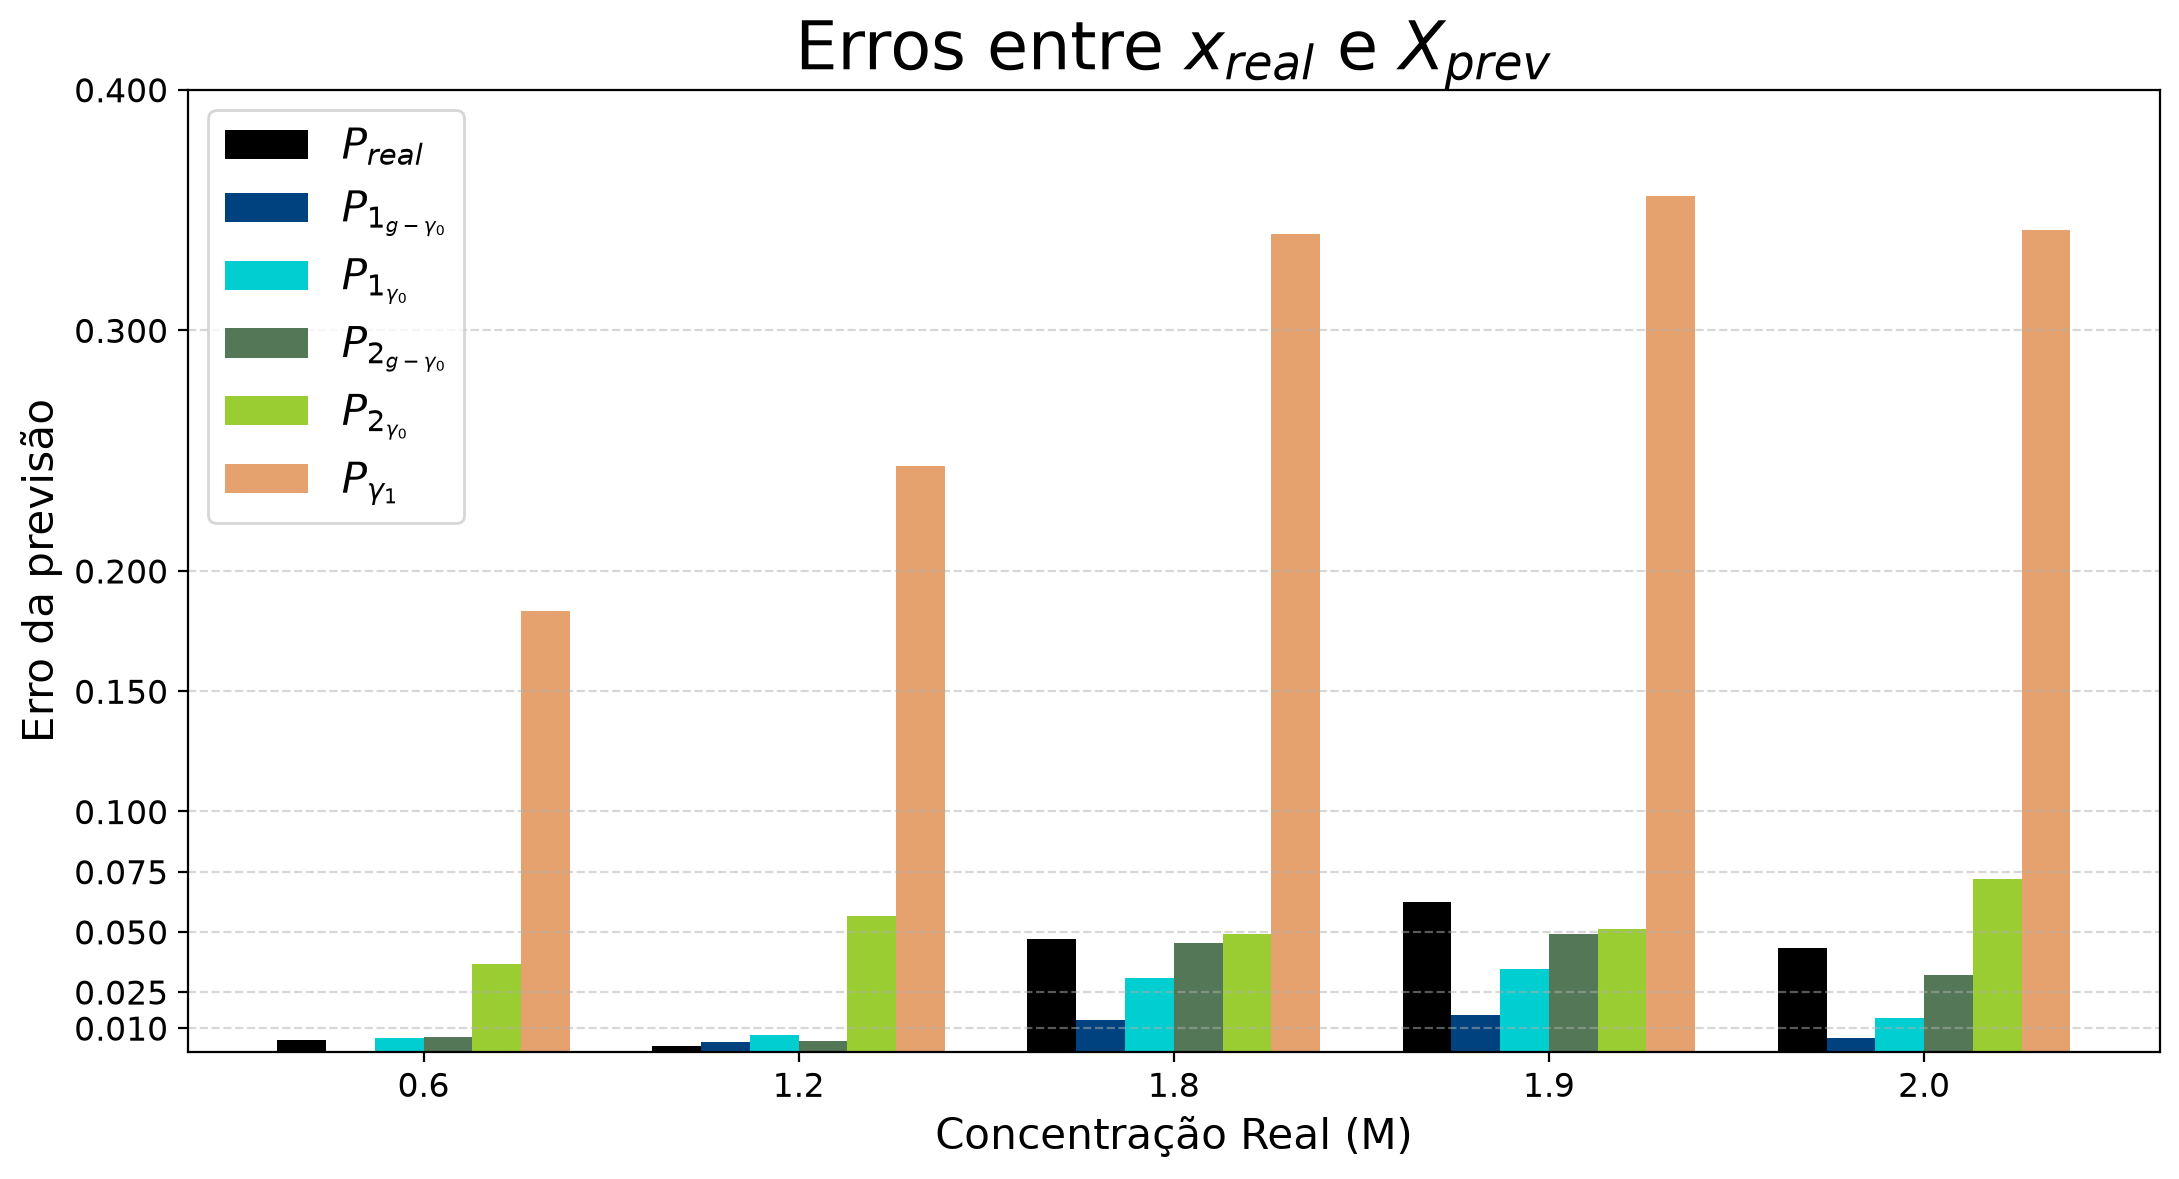

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# ORDENA AS CONCENTRAÇÕES EM ORDEM CRESCENTE
# ============================================================

ordem = np.argsort(xr_prev)

xr = np.array(xr_prev)[ordem]

# Reordena os erros de acordo com a concentração
er  = np.array(erros_real)[ordem]
ei1 = np.array(errosi1)[ordem]
ei2 = np.array(errosi2)[ordem]
eg1 = np.array(errosg1)[ordem]
eg2 = np.array(errosg2)[ordem]
e1  = np.array(erros1)[ordem]


# ============================================================
# POSIÇÕES NO EIXO X
# ============================================================

x = np.arange(len(xr))

# 6 barras por concentração
largura = 0.13


# ============================================================
# GRÁFICO
# ============================================================

plt.figure(figsize=(11, 6), dpi=200)

# ------------------------------------------------------------
# 1 - P_real
# ------------------------------------------------------------
plt.bar(
    x - 2.5 * largura,
    er,
    width=largura,
    color="black",
    label=r"$P_{real}$"
)

# ------------------------------------------------------------
# 2 - P1_g-gamma0
# ------------------------------------------------------------
plt.bar(
    x - 1.5 * largura,
    eg1,
    width=largura,
    color="#00427f",
    label=r"$P_{1_{g-\gamma_0}}$"
)

# ------------------------------------------------------------
# 3 - P1_gamma0
# ------------------------------------------------------------
plt.bar(
    x - 0.5 * largura,
    ei1,
    width=largura,
    color="darkturquoise",
    label=r"$P_{1_{\gamma_0}}$"
)

# ------------------------------------------------------------
# 4 - P2_g-gamma0
# ------------------------------------------------------------
plt.bar(
    x + 0.5 * largura,
    eg2,
    width=largura,
    color="#547757",
    label=r"$P_{2_{g-\gamma_0}}$"
)

# ------------------------------------------------------------
# 5 - P2_gamma0
# ------------------------------------------------------------
plt.bar(
    x + 1.5 * largura,
    ei2,
    width=largura,
    color="yellowgreen",
    label=r"$P_{2_{\gamma_0}}$"
)

# ------------------------------------------------------------
# 6 - P_gamma1
# ------------------------------------------------------------
plt.bar(
    x + 2.5 * largura,
    e1,
    width=largura,
    color="#e5a26e",
    label=r"$P_{\gamma_1}$"
)


# ============================================================
# EIXOS
# ============================================================

plt.xticks(x, xr)
plt.yticks([0.01,0.025,0.05,0.075, 0.1,0.15, 0.2,0.3, 0.4])

plt.tick_params(axis="x", labelsize=12)
plt.tick_params(axis="y", labelsize=12)


plt.xlabel("Concentração Real (M)", fontsize=15)
plt.ylabel("Erro da previsão", fontsize=15)

plt.title(r"Erros entre $x_{real}$ e $X_{prev}$", fontsize=24)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.legend(fontsize=15)

plt.tight_layout()


# ============================================================
# SALVAR
# ============================================================

plt.savefig(
    "erros_xreal_xprevs_barras.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



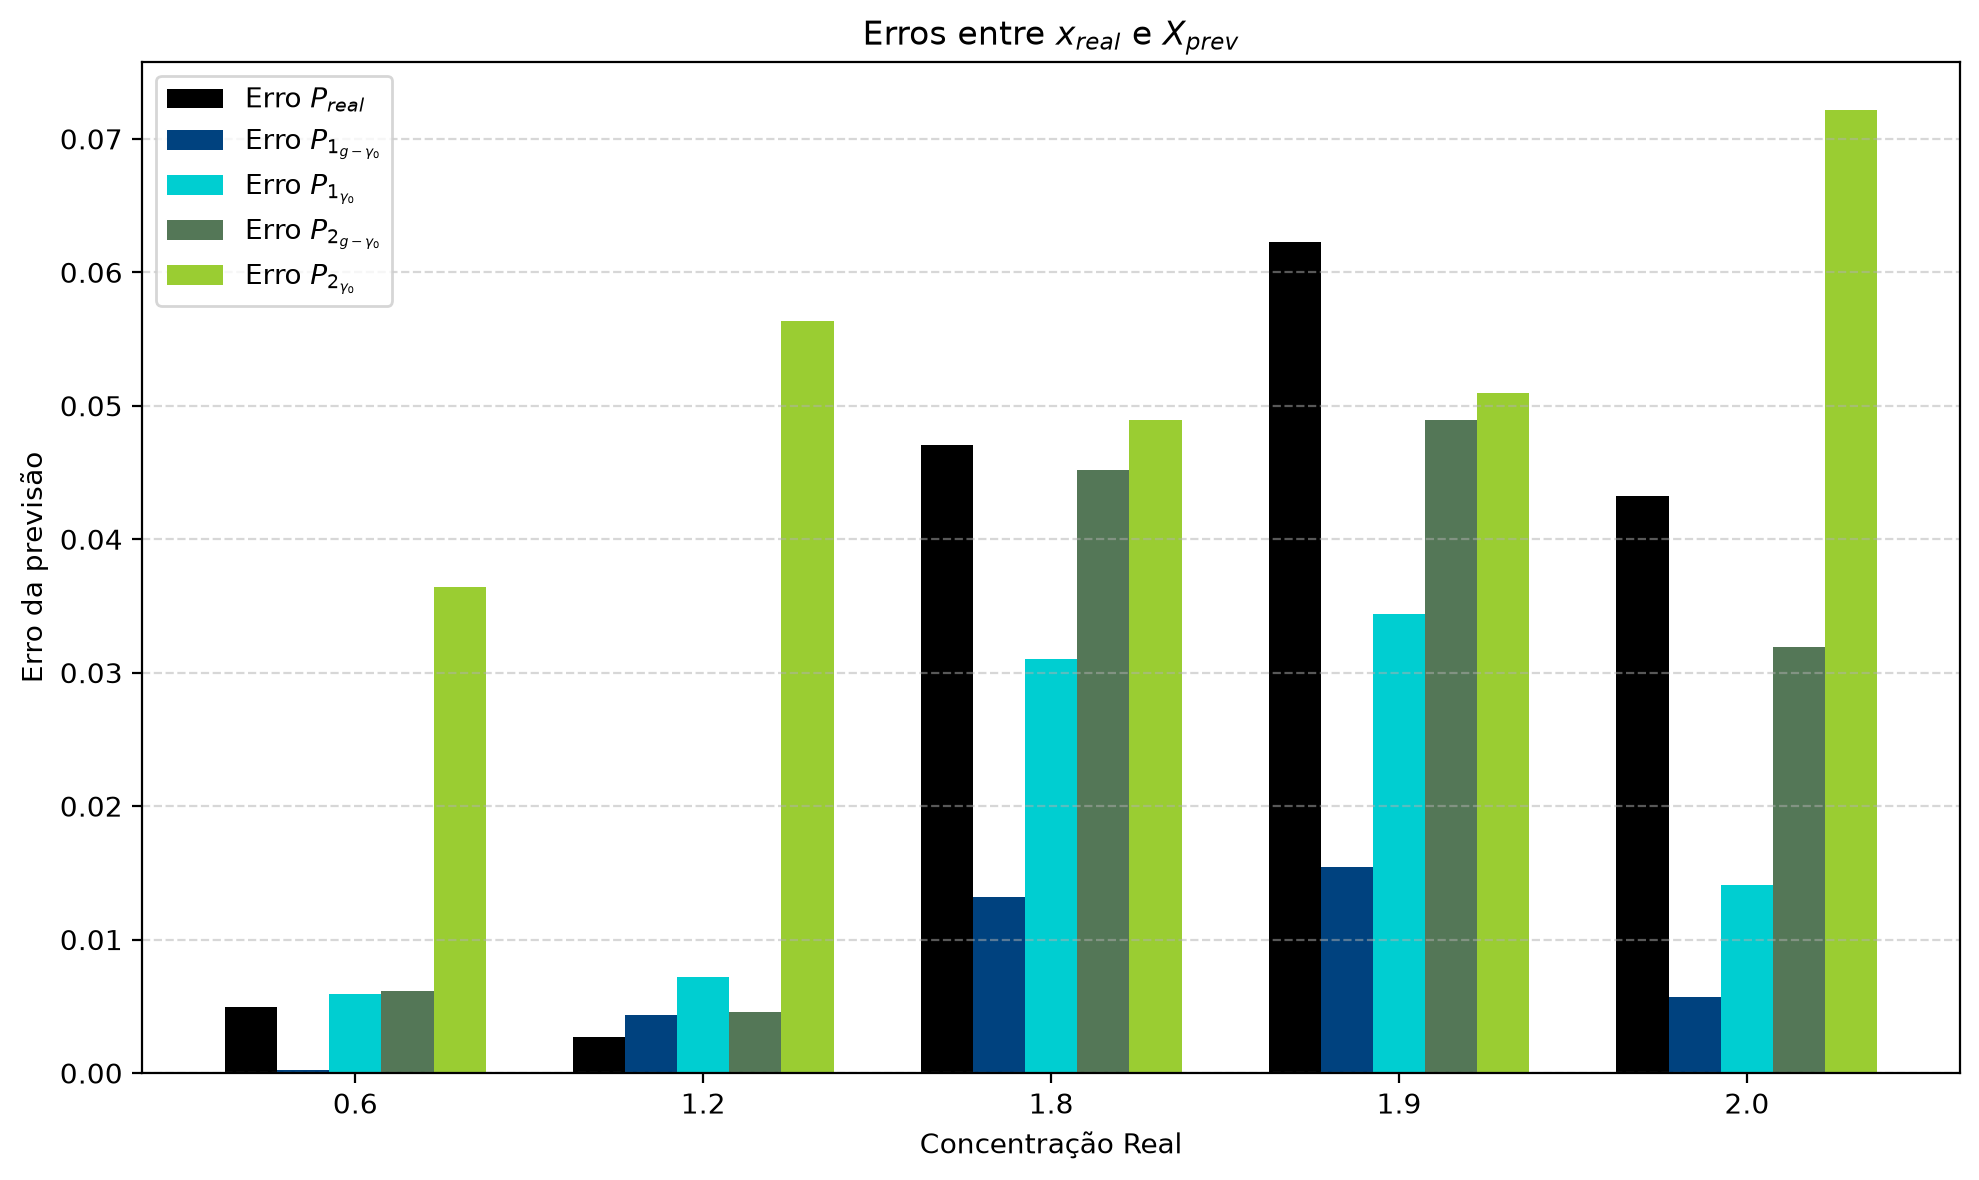

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Ordena as concentrações em ordem crescente
ordem = np.argsort(xr_prev)

xr = np.array(xr_prev)[ordem]

# Reordena os erros de acordo com a concentração
er = np.array(erros_real)[ordem]
eg1 = np.array(errosg1)[ordem]
e1 = np.array(errosi1)[ordem]
eg2 = np.array(errosg2)[ordem]
e2 = np.array(errosi2)[ordem]

# Posições no eixo X
x = np.arange(len(xr))

# Largura das barras
largura = 0.15

plt.figure(figsize=(10, 6), dpi=200)

# Ordem das barras:
# P_real -> P1g -> P1 -> P2g -> P2

plt.bar(
    x - 2*largura,
    er,
    largura,
    color="black",
    label=r"Erro $P_{real}$"
)

plt.bar(
    x - largura,
    eg1,
    largura,
    color="#00427f",
    label=r"Erro $P_{1_{g-\gamma_{0}}}$"
)

plt.bar(
    x,
    e1,
    largura,
    color="darkturquoise",
    label=r"Erro $P_{1_{\gamma_{0}}}$"
)

plt.bar(
    x + largura,
    eg2,
    largura,
    color="#547757",
    label=r"Erro $P_{2_{g-\gamma_{0}}}$"
)

plt.bar(
    x + 2*largura,
    e2,
    largura,
    color="yellowgreen",
    label=r"Erro $P_{2_{\gamma_{0}}}$"
)

# Eixo X em ordem crescente
plt.xticks(x, xr)

plt.title(r"Erros entre $x_{real}$ e $X_{prev}$")
plt.xlabel("Concentração Real")
plt.ylabel("Erro da previsão")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    "erros_xreal_xprevs_barras.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()